# NN ball tracking
Faster R-CNN (ResNet-50 FPN, COCO-pretrained) fine-tuned on SoccerNet ball boxes → static-ball penalty → Kalman filter.
Shared code (data loading, tracker, evaluation) is in `common.py`.

In [1]:
import os, time, json, random
import numpy as np, cv2, pandas as pd, matplotlib.pyplot as plt, torch
from joblib import Parallel, delayed
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from common import *

OUT, CACHE = 'results/nn', 'cache/nn'
TRAIN_STEP, EPOCHS, BATCH, LR = 10, 4, 2, 0.01
PEN = 0.5  # static penalty
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
os.makedirs(OUT, exist_ok=True)
os.makedirs(f'{CACHE}/frames', exist_ok=True)
random.seed(0)
torch.manual_seed(0)
print(dev)

cuda


## SoccerNet data

In [2]:
train_seqs, val_seqs = load_soccernet()
print(len(train_seqs), 'train seqs,', len(val_seqs), 'val seqs')

def cache_seq(s, step):
    out = []
    for f in range(1, s['n'] + 1, step):
        p = f"{CACHE}/frames/{s['name']}_{f:06d}.jpg"
        if not os.path.exists(p):
            cv2.imwrite(p, read_frame(s, f), [cv2.IMWRITE_JPEG_QUALITY, 95])
        out.append((p, s['ball'].get(f)))
    return out

train_set = sum(Parallel(n_jobs=-1)(delayed(cache_seq)(s, TRAIN_STEP) for s in train_seqs), [])
val_set = sum(Parallel(n_jobs=-1)(delayed(cache_seq)(s, 25) for s in val_seqs), [])
print(len(train_set), 'train images,', sum(b is not None for _, b in train_set), 'with ball,', len(val_set), 'val images')

86 train seqs, 20 val seqs
6450 train images, 5997 with ball, 600 val images


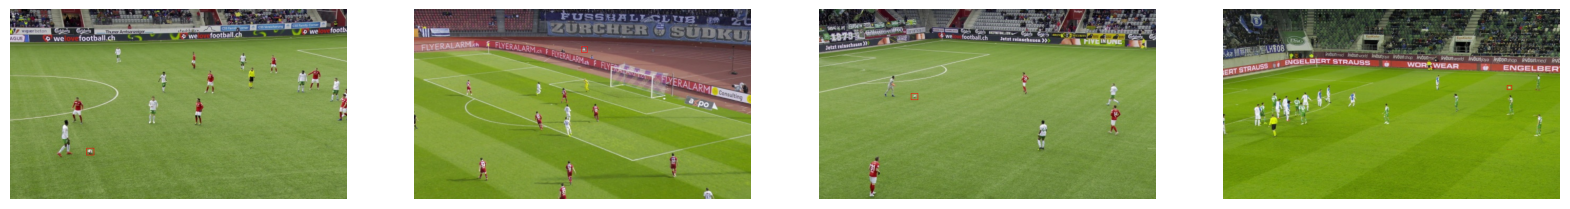

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, (p, b) in zip(ax, random.sample(train_set, 4)):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    if b is not None:
        cv2.rectangle(im, (int(b[0]) - 3, int(b[1]) - 3), (int(b[2]) + 3, int(b[3]) + 3), (255, 0, 0), 1)
    a.imshow(im)
    a.axis('off')

## Model and augmentation

In [4]:
def build_model():
    m = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1, min_size=720, max_size=1280,  # 2x upscale
                                box_score_thresh=0.01, box_detections_per_img=20)
    m.rpn.anchor_generator = AnchorGenerator(((8,), (16,), (32,), (64,), (128,)), ((0.5, 1.0, 2.0),) * 5)  # small anchors
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 2)  # ball, background
    return m.to(dev)

def to_tensor(im):
    return torch.from_numpy(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255).to(dev)

def sample(p, b):
    im = cv2.imread(p)
    box = np.zeros((0, 4), np.float32) if b is None else b[None].astype(np.float32)
    if random.random() < 0.5:  # flip
        im = im[:, ::-1].copy()
        box[:, [0, 2]] = W - box[:, [2, 0]]
    if random.random() < 0.3:  # zoom
        z = random.uniform(1.0, 2.0)
        cw, ch = int(W / z), int(H / z)
        if len(box):
            cx, cy = center(box[0])
            x0 = int(np.clip(cx - random.uniform(0.1, 0.9) * cw, 0, W - cw))
            y0 = int(np.clip(cy - random.uniform(0.1, 0.9) * ch, 0, H - ch))
        else:
            x0, y0 = random.randint(0, W - cw), random.randint(0, H - ch)
        im = cv2.resize(im[y0:y0 + ch, x0:x0 + cw], (W, H))
        box = ((box - [x0, y0, x0, y0]) * [W / cw, H / ch, W / cw, H / ch]).astype(np.float32)
    if random.random() < 0.5:  # brightness
        im = cv2.convertScaleAbs(im, alpha=random.uniform(0.8, 1.2), beta=random.uniform(-20, 20))
    if random.random() < 0.3:  # colour
        hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV).astype(np.int16)
        hsv[..., 0] = (hsv[..., 0] + random.randint(-4, 4)) % 180
        hsv[..., 1] = np.clip(hsv[..., 1] * random.uniform(0.7, 1.3), 0, 255)
        im = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)
    if random.random() < 0.3:  # blur
        im = cv2.GaussianBlur(im, (0, 0), random.uniform(0.5, 1.2))
    if random.random() < 0.5:  # compression
        im = cv2.imdecode(cv2.imencode('.jpg', im, [cv2.IMWRITE_JPEG_QUALITY, random.randint(15, 60)])[1], cv2.IMREAD_COLOR)
    target = dict(boxes=torch.from_numpy(box).to(dev), labels=torch.ones(len(box), dtype=torch.int64, device=dev))
    return to_tensor(im), target

## Training (transfer learning from COCO)

Text(0.5, 0, 'iteration')

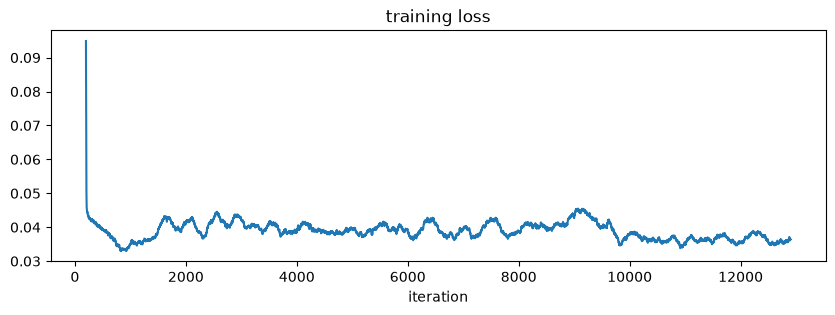

In [5]:
WEIGHTS = f'{OUT}/frcnn_ball_5games.pt'
model = build_model()
if os.path.exists(WEIGHTS):
    model.load_state_dict(torch.load(WEIGHTS, map_location=dev))
    hist = pd.read_csv(f'{OUT}/train_loss_5games.csv')
else:
    opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=LR, momentum=0.9, weight_decay=1e-4)
    iters = EPOCHS * (len(train_set) // BATCH)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / 500) * (0.1 if i > 0.75 * iters else 1))  # warmup, step
    scaler = torch.amp.GradScaler()
    hist, t0 = [], time.time()
    model.train()
    for ep in range(EPOCHS):
        random.shuffle(train_set)
        for i in range(0, len(train_set) - BATCH + 1, BATCH):
            imgs, tgts = zip(*[sample(p, b) for p, b in train_set[i:i + BATCH]])
            with torch.autocast(dev, dtype=torch.float16):
                losses = model(list(imgs), list(tgts))
                loss = sum(losses.values())
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            hist.append(dict(epoch=ep, loss=loss.item(), **{k: v.item() for k, v in losses.items()}))
            if len(hist) % 500 == 0:
                print(f'ep {ep} it {len(hist)}/{iters} loss {np.mean([h["loss"] for h in hist[-500:]]):.3f} {time.time() - t0:.0f}s')
    hist = pd.DataFrame(hist)
    hist.to_csv(f'{OUT}/train_loss_5games.csv', index=False)
    torch.save(model.state_dict(), WEIGHTS)
model.eval()
hist.loss.rolling(200).mean().plot(figsize=(10, 3), title='training loss')
plt.xlabel('iteration')

## Validation (game 9): detection ranking

In [6]:
@torch.no_grad()
def detect(frames, bs=4):
    out = []
    for i in range(0, len(frames), bs):
        with torch.autocast(dev, dtype=torch.float16):
            res = model([to_tensor(f) for f in frames[i:i + bs]])
        for o in res:
            b, s = o['boxes'].float().cpu().numpy(), o['scores'].float().cpu().numpy()
            out.append((np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2], s))
    return out

def rank_eval(dets, boxes, r=4):
    top1, top5 = [], []
    for (xy, _), b in zip(dets, boxes):
        if b is None:
            continue
        d = np.hypot(*(xy - center(b)).T) if len(xy) else np.array([1e9])
        top1.append(d[0] <= r)
        top5.append((d[:5] <= r).any())
    return np.mean(top1), np.mean(top5)

val_dets = detect([cv2.imread(p) for p, _ in val_set])
print('top1 %.3f, top5 %.3f' % rank_eval(val_dets, [b for _, b in val_set]))

top1 0.725, top5 0.838


## Validation: tracking

In [7]:
VAL_TRACK = val_seqs[::3]
names = [s['name'] for s in VAL_TRACK]
val_scores = cached(f'{CACHE}/val_scores_5games.pkl',
                    lambda: {s['name']: detect([read_frame(s, f) for f in range(1, s['n'] + 1)]) for s in VAL_TRACK})
val_H = cached(f'{CACHE}/val_H.pkl', lambda: dict(zip(names, Parallel(n_jobs=-1)(delayed(seq_homographies)(s) for s in VAL_TRACK))))
val_gt = {s['name']: {f - 1: center(b) for f, b in s['ball'].items()} for s in VAL_TRACK}

def penalise(scores, Hs):
    return [(xy, np.where(m, sc * PEN, sc)) for (xy, sc), m in zip(scores, static_mask(scores, Hs, 0.3))]

val_pen = {n: penalise(val_scores[n], val_H[n]) for n in names}

grid = []
for ti in [0.3, 0.5, 0.7]:
    for tk in [0.05, 0.1, 0.2]:
        kw = dict(t_init=ti, t_keep=tk, t_switch=min(ti + 0.2, 0.95), margin=0.3)
        grid.append(dict(**kw, **evaluate(lambda sc: run_tracker(sc, **kw), val_scores, val_gt)))
grid = pd.DataFrame(grid).sort_values('F1', ascending=False)
grid.head()

,t_init,t_keep,t_switch,margin,precision,recall,F1,err_px
3,0.5,0.05,0.7,0.3,0.868550,0.875767,0.872143,1.002540
5,0.5,0.20,0.7,0.3,0.872324,0.870425,0.871373,1.006530
4,0.5,0.10,0.7,0.3,0.868286,0.869832,0.869058,1.001898
8,0.7,0.20,0.9,0.3,0.876616,0.858754,0.867593,1.007091
6,0.7,0.05,0.9,0.3,0.861994,0.863699,0.862846,1.004410


SoccerNet has no spare balls, so validation cannot reward the static penalty; `PEN` is a fixed prior (not tuned) and results are shown with and without it.

In [8]:
TRK = grid.iloc[0][['t_init', 't_keep', 't_switch', 'margin']].to_dict()
det = pd.DataFrame([dict(t=t, **evaluate(lambda sc: detect_only(sc, t), val_scores, val_gt)) for t in [0.1, 0.3, 0.5, 0.7, 0.9]])
det = det.sort_values('F1', ascending=False)
json.dump(dict(**TRK, pen=PEN), open(f'{OUT}/tracker_params.json', 'w'))
pd.DataFrame([dict(method='detection only (best t)', **det.iloc[0].drop('t').to_dict()),
              dict(method='detection + Kalman', **evaluate(lambda sc: run_tracker(sc, **TRK), val_scores, val_gt)),
              dict(method='detection + Kalman + static penalty', **evaluate(lambda sc: run_tracker(sc, **TRK), val_pen, val_gt))])

,method,precision,recall,F1,err_px
0,detection only (best t),0.871949,0.777250,0.821881,0.961947
1,detection + Kalman,0.868550,0.875767,0.872143,1.002540
2,detection + Kalman + static penalty,0.849606,0.853808,0.851702,1.009336


## Test clip: Denmark vs Wales

113s, ball reported in 1421/1500 frames


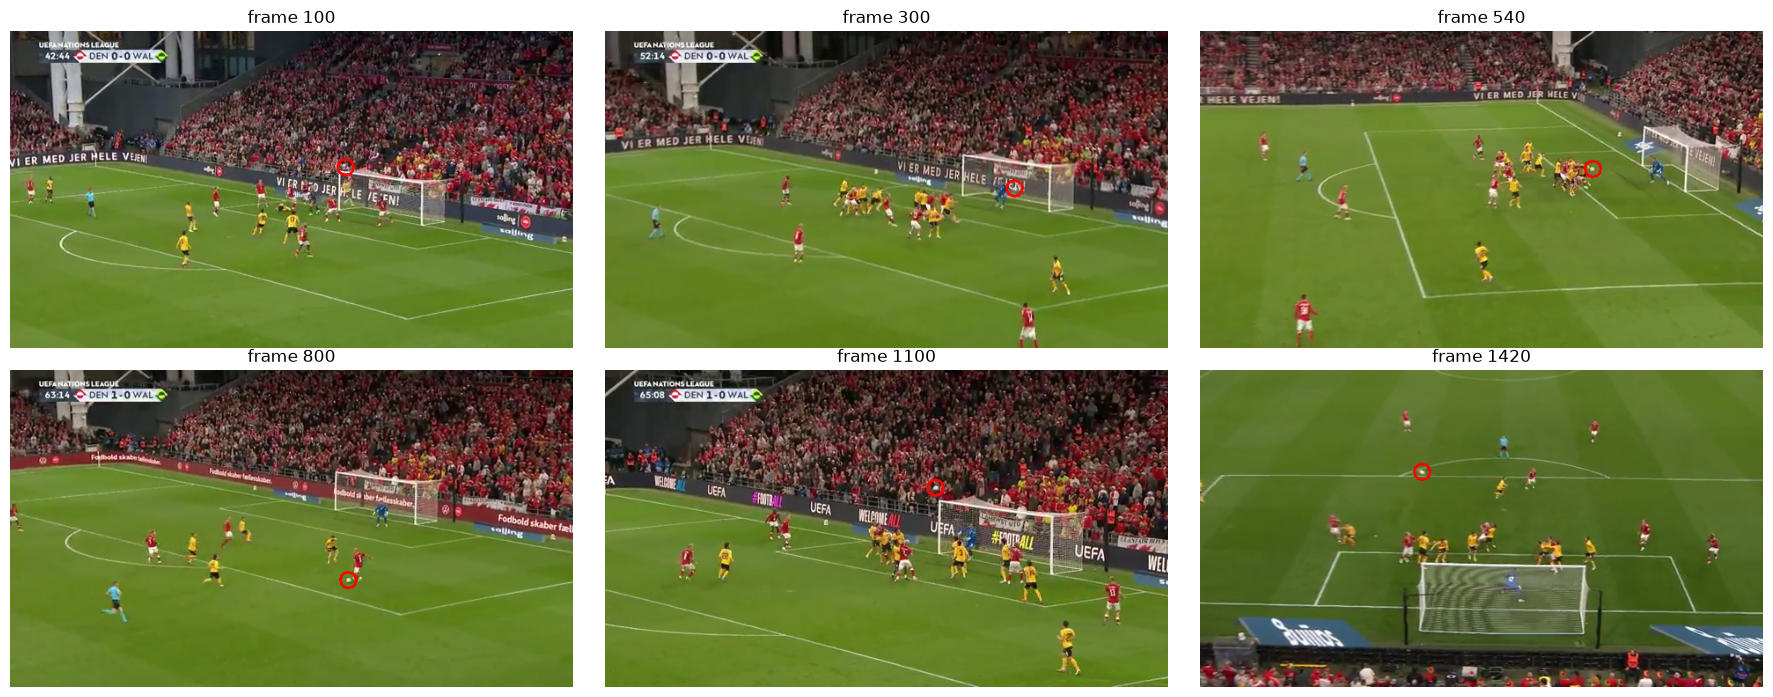

In [9]:
test_frames, fps = read_video()
cuts = [False] + [shot_cut(a, b) for a, b in zip(test_frames[:-1], test_frames[1:])]
t0 = time.time()
test_scores = detect(test_frames)
test_H = homographies([cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in test_frames], cuts)
pred_plain = run_tracker(test_scores, cuts, **TRK)
pred = run_tracker(penalise(test_scores, test_H), cuts, **TRK)
print(f'{time.time() - t0:.0f}s, ball reported in {len(pred)}/{len(test_frames)} frames')
save_predictions(pred, len(test_frames), f'{OUT}/test_predictions.csv')
write_video(test_frames, pred, cuts, fps, f'{OUT}/test_tracking.mp4')
show_frames(test_frames, pred)

## Test evaluation and comparison with non-NN

In [10]:
gt, labelled = load_gt()
rows = [dict(method='NN detection only', **metrics(detect_only(test_scores, det.iloc[0].t), gt, labelled)),
        dict(method='NN detection + Kalman', **metrics(pred_plain, gt, labelled)),
        dict(method='NN detection + Kalman + static penalty', **metrics(pred, gt, labelled))]
if os.path.exists('results/non_nn/test_predictions.csv'):
    rows.append(dict(method='non-NN (final)', **metrics(load_predictions('results/non_nn/test_predictions.csv'), gt, labelled)))
test_res = pd.DataFrame(rows)
test_res.to_csv(f'{OUT}/test_metrics.csv', index=False)
test_res

,method,precision,recall,F1,err_px
0,NN detection only,0.476000,0.533632,0.503171,1.227597
1,NN detection + Kalman,0.424028,0.538117,0.474308,1.299448
2,NN detection + Kalman + static penalty,0.597173,0.757848,0.667984,1.285959
3,non-NN (final),0.516729,0.623318,0.565041,1.689257
